# Online Retail Store, Exploratory Data Analysis
**Khodor El-Rifai**

This notebook explores 541,909 rows from an online retail store between 2010-12-01 and 2011-12-09. The company wants to understand its customers, products, cancellations, sales performance and international markets. 



## Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
from scipy import stats

## Part 1:  Data loading & Audit

In [2]:
df = pd.read_excel('Online Retail 2.xlsx')

In [3]:
df.shape


(541909, 8)

There are 541,909 rows and 8 columns. Each row is one product inside an order.

In [4]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [5]:
df.tail()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France


In [6]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


Two columns have missing values: Description and CustomerID. CustomerID is stored as a float (e.g. 17850.0) because it has missing values (NaN). An ID should not be a decimal number, so it will be converted during cleaning. InvoiceNo is stored as text (object) because some invoice numbers start with letters (“C” and “A”).

In [8]:
missing_count = df.isnull().sum()
missing_prc = (missing_count / len(df) * 100).round(2)

missing_table = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing %": missing_prc
})
missing_table

,Missing Count,Missing %
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00


The biggest problem is with CustomerID, which has 135,080 missing values (24.93%). Only 406,829 rows (75.07%) have a CustomerID, so the segmentation model can only be built on three quarters of the data. We can still count those rows in total sales and use them to analyse product, country and time, even if we don’t have the CustomerID. But we don’t know who bought, how many times a customer bought, or how to segment those customers. Segmentation groups customers by their frequency of purchase, monetary value of purchase and recency of purchase. If customers with no ID have different behaviour, they will be missing from the segments, so the model may not represent the company’s customers in general.

In [9]:
df.duplicated().sum()

np.int64(5268)

In [10]:
df[df.duplicated(keep=False)].sort_values(by=["InvoiceNo", "StockCode"]).head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
565,536412,21448,12 DAISY PEGS IN WOOD BOX,2,2010-12-01 11:49:00,1.65,17920.0,United Kingdom
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom


In [11]:
dup_count = df.duplicated().sum()
dup_prc = round(dup_count / len(df) * 100, 2)
print(dup_count, dup_prc)

5268 0.97


There are 5,268 duplicated rows, which is 0.97%. Rows 494 and 517 for example have the same InvoiceNo, the same product, quantity, price, and customer, and even the same time to the minute. These are probably system errors because everything is identical. If we keep them, those sales are counted twice. Since they are only 0.97% of the data, removing them is fine.


In [12]:
mem = df.memory_usage(deep=True).sum()
mem = mem / 1024 ** 2
print(round(mem, 2), "MB")

126.18 MB


Memory usage is 126.18 MB, which is much bigger than the 33.1+ MB shown by .info(). The ‘+’ means the real size is at least 33.1 MB, but the text columns are not fully counted. deep=True counts everything, including the text inside the text columns, which uses much more memory than numbers.


In [13]:
df.nunique()

InvoiceNo      25900
StockCode       4070
Description     4223
Quantity         722
InvoiceDate    23260
UnitPrice       1630
CustomerID      4372
Country           38
dtype: int64

There are 25,900 orders, 4,372 customers, 4,070 products and 38 countries. On average, each order has about 21 product lines (541,909 rows ÷ 25,900 orders). There are 4,223 descriptions but only 4,070 product codes, which means some products have more than one description.


In [14]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


The median quantity is 3 and the median unit price is 2.08. But the minimum values are negative: negative quantities are cancellations, and negative prices are bad debt adjustments. The maximum values are also very large. The max quantity of 80,995 was one order that was cancelled 12 minutes later. These values are investigated in the cells below.

In [15]:
cancelled = df["InvoiceNo"].astype(str).str.startswith("C")
print(cancelled.sum())

9288


There are 9,288 cancelled rows (1.71% of all rows). Invoices that start with “C” are cancellations. This matters because the company asked to understand cancellations, so these rows should not just be deleted. They will be analysed separately.

In [16]:
neg_qty = df[df["Quantity"] < 0]
neg_qty.head()


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


In [17]:
print(len(neg_qty))

10624


There are 10,624 rows with a negative quantity, but only 9,288 cancelled rows. This means most negative quantities are cancellations, but 1,336 rows are negative without being cancelled.

In [18]:
df[df["UnitPrice"] < 0]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


There are only 2 rows with a negative unit price (-11,062.06). Both have invoices starting with “A”, the description “Adjust bad debt” and no CustomerID. These are accounting adjustments, not sales, so they should not be counted in total sales.

In [19]:
neg_not_canc = df[ (df["Quantity"] < 0) & ( ~cancelled) ]
print(len(neg_not_canc))

1336


In [20]:
neg_not_canc.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom
4347,536764,84952C,NaN,-38,2010-12-02 14:42:00,0.0,NaN,United Kingdom
7188,536996,22712,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7189,536997,22028,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7190,536998,85067,NaN,-6,2010-12-03 15:30:00,0.0,NaN,United Kingdom


In [21]:
print("Unique prices:", neg_not_canc["UnitPrice"].unique())

Unique prices: [0.]


In [22]:
print("Missing CustomerID:", neg_not_canc["CustomerID"].isnull().sum(), "out of", len(neg_not_canc))

Missing CustomerID: 1336 out of 1336


In [23]:
print(neg_not_canc["Description"].value_counts().head(15))

Description
check                     120
damages                    45
damaged                    42
?                          41
sold as set on dotcom      20
Damaged                    14
thrown away                 9
Unsaleable, destroyed.      9
??                          7
wet damaged                 5
damages?                    5
ebay                        5
smashed                     4
missing                     3
wet pallet                  3
Name: count, dtype: int64


All 1,336 rows have a unit price of 0 and no CustomerID. Their descriptions include words like “damaged”, “thrown away”, “missing” and “check”. They are neither sales nor cancellations. They appear to be internal stock adjustments, where the company records damaged or lost items.

In [24]:
df[df["Quantity"].abs() == 80995]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446.0,United Kingdom


The same customer (16446) ordered 80,995 units of “PAPER CRAFT, LITTLE BIRDIE” at 09:15 and cancelled the whole order 12 minutes later (invoice C581484). The order was worth about 168,000. If only the cancellation row is removed, the original order stays in the data and makes this product look like the best-selling product, even though the sale never really happened. Both rows need to be handled together.

### Audit summary
- CustomerID: 135,080 missing values (24.93%)
- Description: 1,454 missing values (0.27%)
- Duplicate rows: 5,268 (0.97%)
- Cancelled rows (invoice starts with "C"): 9,288 (1.71%)
- Stock adjustments (negative quantity, not cancelled): 1,336 rows
- Bad debt adjustments (invoice starts with "A"): 2 rows
- One order of 80,995 units, cancelled 12 minutes later
- CustomerID stored as float instead of a whole number
- Products with more than one description: 4,223 descriptions for 4,070 product codes

## Preparing the sales data

I am removing some of the data (duplicate rows, cancelled rows, stock adjustments, and bad debt adjustments) that we found a problem with in Part 1. It will help us make correct charts of sales and revenue. Also, the df will be kept unchanged for the cancellation analysis.

In [25]:
sales = df.copy()

In [26]:
sales = sales.drop_duplicates()

In [27]:
print(len(sales))

536641


In [28]:
sales = sales[ (sales["Quantity"] > 0) & (sales["UnitPrice"] > 0) ]
print("Rows after keeping only real sales",len(sales))

Rows after keeping only real sales 524878


All the cancellations were removed, as there are no more negative values.

In [29]:
sales["Revenue"] = sales["Quantity"] * sales["UnitPrice"]

In [30]:
sales.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [31]:
sales.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID,Revenue
count,524878.000000,524878,524878.000000,392692.000000,524878.000000
mean,10.616600,2011-07-04 15:30:16.317049088,3.922573,15287.843865,20.275399
min,1.000000,2010-12-01 08:26:00,0.001000,12346.000000,0.001000
25%,1.000000,2011-03-28 12:13:00,1.250000,13955.000000,3.900000
50%,4.000000,2011-07-20 11:22:00,2.080000,15150.000000,9.920000
75%,11.000000,2011-10-19 11:41:00,4.130000,16791.000000,17.700000
max,80995.000000,2011-12-09 12:50:00,13541.330000,18287.000000,168469.600000
std,156.280031,NaN,36.093028,1713.539549,271.693566


In [32]:
sales.sort_values(by=["InvoiceNo", "StockCode"] ,ascending = False).head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
299982,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,NaN,United Kingdom,11062.06
541903,581587,23256,CHILDRENS CUTLERY SPACEBOY,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,12.60
541900,581587,22730,ALARM CLOCK BAKELIKE IVORY,4,2011-12-09 12:50:00,3.75,12680.0,France,15.00
541897,581587,22728,ALARM CLOCK BAKELIKE PINK,4,2011-12-09 12:50:00,3.75,12680.0,France,15.00
541898,581587,22727,ALARM CLOCK BAKELIKE RED,4,2011-12-09 12:50:00,3.75,12680.0,France,15.00
541899,581587,22726,ALARM CLOCK BAKELIKE GREEN,4,2011-12-09 12:50:00,3.75,12680.0,France,15.00
541894,581587,22631,CIRCUS PARADE LUNCH BOX,12,2011-12-09 12:50:00,1.95,12680.0,France,23.40


In [33]:
bad_debt = sales["InvoiceNo"].astype(str).str.startswith("A")
print("Bad debt rows left in sales:", bad_debt.sum())

Bad debt rows left in sales: 1


In [34]:
sales.sort_values(by=["Quantity"] ,ascending = False).head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom,168469.60
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346.0,United Kingdom,77183.60
421632,573008,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,2011-10-27 12:26:00,0.21,12901.0,United Kingdom,1008.00
206121,554868,22197,SMALL POPCORN HOLDER,4300,2011-05-27 10:52:00,0.72,13135.0,United Kingdom,3096.00
97432,544612,22053,EMPIRE DESIGN ROSETTE,3906,2011-02-22 10:43:00,0.82,18087.0,United Kingdom,3202.92
270885,560599,18007,ESSENTIAL BALM 3.5g TIN IN ENVELOPE,3186,2011-07-19 17:04:00,0.06,14609.0,United Kingdom,191.16
52711,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2011-01-11 12:55:00,2.10,15749.0,United Kingdom,6539.40
160546,550461,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2011-04-18 13:20:00,2.10,15749.0,United Kingdom,6539.40
433788,573995,16014,SMALL CHINESE STYLE SCISSOR,3000,2011-11-02 11:24:00,0.32,16308.0,United Kingdom,960.00
4945,536830,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,2880,2010-12-02 17:38:00,0.18,16754.0,United Kingdom,518.40


In [35]:
df[df["Quantity"].abs() == 74215]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346.0,United Kingdom
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346.0,United Kingdom


In [36]:
df[df["InvoiceNo"] == "A563185"]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299982,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,NaN,United Kingdom


In [37]:
remove_invoice = ["581483", "541431", "A563185", "556444"]

In [38]:
sales = sales[~sales["InvoiceNo"].astype(str).isin(remove_invoice)]
print(len(sales))

524874


In [39]:
sales.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID,Revenue
count,524874.000000,524874,524874.000000,392689.000000,524874.000000
mean,10.320856,2011-07-04 15:30:15.414784768,3.900283,15287.848891,19.712208
min,1.000000,2010-12-01 08:26:00,0.001000,12347.000000,0.001000
25%,1.000000,2011-03-28 12:13:00,1.250000,13955.000000,3.900000
50%,4.000000,2011-07-20 11:22:00,2.080000,15150.000000,9.920000
75%,11.000000,2011-10-19 11:41:00,4.130000,16791.000000,17.700000
max,4800.000000,2011-12-09 12:50:00,13541.330000,18287.000000,13541.330000
std,37.914173,NaN,32.694752,1713.538640,72.731757


In [40]:
sales.sort_values(by=["UnitPrice"] ,ascending = False).head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
15017,537632,AMAZONFEE,AMAZON FEE,1,2010-12-07 15:08:00,13541.33,NaN,United Kingdom,13541.33
173382,551697,POST,POSTAGE,1,2011-05-03 13:46:00,8142.75,16029.0,United Kingdom,8142.75
297723,562955,DOT,DOTCOM POSTAGE,1,2011-08-11 10:14:00,4505.17,NaN,United Kingdom,4505.17
268028,560373,M,Manual,1,2011-07-18 12:30:00,4287.63,NaN,United Kingdom,4287.63
422351,573077,M,Manual,1,2011-10-27 14:13:00,4161.06,12536.0,France,4161.06
422376,573080,M,Manual,1,2011-10-27 14:20:00,4161.06,12536.0,France,4161.06
406406,571751,M,Manual,1,2011-10-19 11:18:00,3949.32,12744.0,Singapore,3949.32
374542,569382,M,Manual,1,2011-10-03 16:44:00,3155.95,15502.0,United Kingdom,3155.95
347948,567353,M,Manual,1,2011-09-19 16:14:00,2653.95,NaN,Hong Kong,2653.95
119632,546558,M,Manual,1,2011-03-15 09:50:00,2583.76,NaN,Hong Kong,2583.76


In [41]:
sales.sort_values(by=["Revenue"] ,ascending = False).head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
15017,537632,AMAZONFEE,AMAZON FEE,1,2010-12-07 15:08:00,13541.33,NaN,United Kingdom,13541.33
173382,551697,POST,POSTAGE,1,2011-05-03 13:46:00,8142.75,16029.0,United Kingdom,8142.75
348325,567423,23243,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,2011-09-20 11:05:00,5.06,17450.0,United Kingdom,7144.72
52711,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2011-01-11 12:55:00,2.10,15749.0,United Kingdom,6539.40
160546,550461,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2011-04-18 13:20:00,2.10,15749.0,United Kingdom,6539.40
421601,573003,23084,RABBIT NIGHT LIGHT,2400,2011-10-27 12:11:00,2.08,14646.0,Netherlands,4992.00
52709,540815,85123A,WHITE HANGING HEART T-LIGHT HOLDER,1930,2011-01-11 12:55:00,2.55,15749.0,United Kingdom,4921.50
467804,576365,22086,PAPER CHAIN KIT 50'S CHRISTMAS,688,2011-11-14 17:55:00,6.95,NaN,United Kingdom,4781.60
160542,550461,85123A,WHITE HANGING HEART T-LIGHT HOLDER,1930,2011-04-18 13:20:00,2.40,15749.0,United Kingdom,4632.00
52772,540818,48185,DOORMAT FAIRY CAKE,670,2011-01-11 12:57:00,6.75,15749.0,United Kingdom,4522.50


In [42]:
df[(df["CustomerID"] == 15098) & (df["StockCode"] == 22502)]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
222670,556442,22502,PICNIC BASKET WICKER SMALL,60,2011-06-10 15:22:00,4.95,15098.0,United Kingdom
222680,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,2011-06-10 15:28:00,649.50,15098.0,United Kingdom
222682,556446,22502,PICNIC BASKET WICKER 60 PIECES,1,2011-06-10 15:33:00,649.50,15098.0,United Kingdom
222692,C556448,22502,PICNIC BASKET WICKER SMALL,-60,2011-06-10 15:39:00,4.95,15098.0,United Kingdom


In [43]:
print(len(sales))

524874


In [44]:
un_pdt = ~sales["StockCode"].astype(str).str[0].str.isdigit()

In [45]:
sales[un_pdt]["Description"].value_counts()

Description
POSTAGE                               1126
DOTCOM POSTAGE                         706
Manual                                 317
CARRIAGE                               141
GIRLS PARTY BAG                         13
Bank Charges                            12
BOYS PARTY BAG                          11
Dotcomgiftshop Gift Voucher £20.00       9
Dotcomgiftshop Gift Voucher £10.00       8
Dotcomgiftshop Gift Voucher £30.00       7
Dotcomgiftshop Gift Voucher £50.00       4
BOXED GLASS ASHTRAY                      4
Dotcomgiftshop Gift Voucher £40.00       3
PADS TO MATCH ALL CUSHIONS               3
SUNJAR LED NIGHT NIGHT LIGHT             2
AMAZON FEE                               2
SAMPLES                                  2
CAMOUFLAGE DOG COLLAR                    1
OOH LA LA DOGS COLLAR                    1
HAYNES CAMPER SHOULDER BAG               1
Name: count, dtype: int64

In [46]:
remove_desc = ["POSTAGE", "DOTCOM POSTAGE", "Manual", "CARRIAGE", "Bank Charges", "AMAZON FEE", "SAMPLES"]

In [47]:
sales = sales[~sales["Description"].isin(remove_desc)]

In [48]:
print(len(sales))

522568


In [49]:
sales.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID,Revenue
count,522568.000000,522568,522568.000000,391150.000000,522568.000000
mean,10.345352,2011-07-04 16:40:48.300202240,3.273819,15295.176257,19.066001
min,1.000000,2010-12-01 08:26:00,0.001000,12347.000000,0.001000
25%,1.000000,2011-03-28 12:13:00,1.250000,13969.000000,3.900000
50%,4.000000,2011-07-20 11:55:00,2.080000,15159.000000,9.900000
75%,12.000000,2011-10-19 11:44:00,4.130000,16794.000000,17.700000
max,4800.000000,2011-12-09 12:50:00,649.500000,18287.000000,7144.720000
std,37.852905,NaN,4.304220,1710.333549,65.305710


# Part 2 Analysis charts

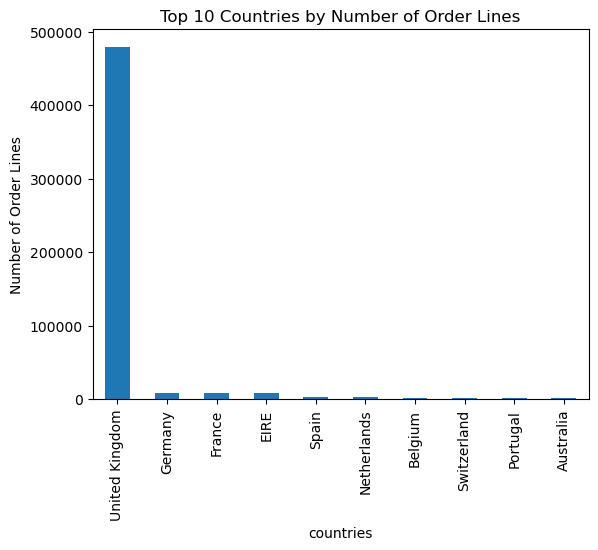

In [50]:
sales["Country"].value_counts().head(10).plot(kind = "bar")
plt.title("Top 10 Countries by Number of Order Lines")
plt.xlabel("countries")
plt.ylabel("Number of Order Lines")
plt.show()

The UK has ~480,000 orders, and Germany has 9,000 orders; the UK is 50 times bigger than Germany. Most of the business is from the UK, probably because the company is UK-based, especially since it gives gift vouchers in pounds.

In [51]:
non_UK_sales = sales["Country"] != "United Kingdom"

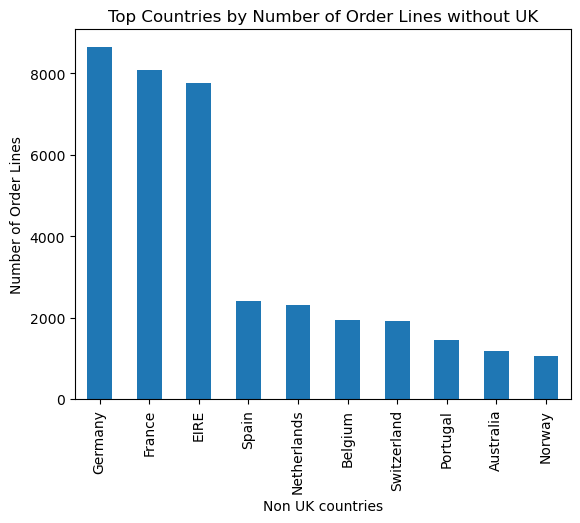

In [52]:
sales[non_UK_sales]["Country"].value_counts().head(10).plot(kind = "bar")
plt.title("Top Countries by Number of Order Lines without UK")
plt.xlabel("Non UK countries")
plt.ylabel("Number of Order Lines")
plt.show()

The top 3 countries, Germany, France, and Ireland (EIRE), are all close to the UK, which might make shipping easier, as for being close, they have about three times the number of order lines as Spain and the other countries. The company should focus on growing internationally, especially in Spain and the Netherlands, and these countries have many fewer order lines.  

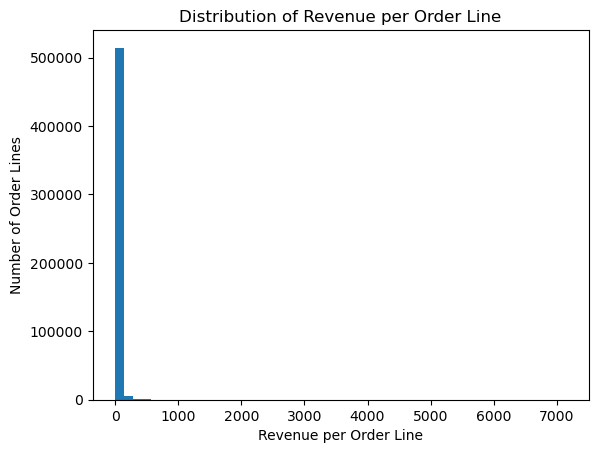

In [53]:
sales["Revenue"].plot(kind = "hist", bins = 50)
plt.title("Distribution of Revenue per Order Line")
plt.xlabel("Revenue per Order Line")
plt.ylabel("Number of Order Lines")
plt.show()

Almost all order lines are in the first bar under about 150; the axis goes to 7,000 because of few very large orders. So, most purchases are small, with a few big wholesale orders.

In [54]:
s_l = sales[sales["Revenue"] <= 100]

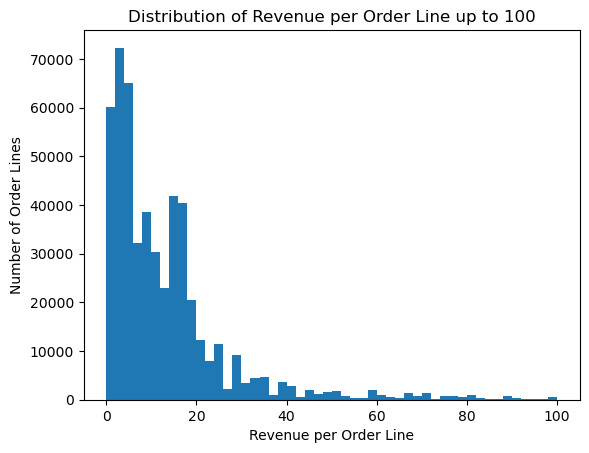

In [55]:
s_l["Revenue"].plot(kind = "hist", bins = 50)
plt.title("Distribution of Revenue per Order Line up to 100")
plt.xlabel("Revenue per Order Line")
plt.ylabel("Number of Order Lines")
plt.show()

In [56]:
small_prc = round(len(s_l) / len(sales) *100, 2 )
print(small_prc)

97.58


The percentage of order lines that are 100 or less is 97.58%, where the tallest bar is the most common revenue per line (2-4). After 20, the number of order lines drops as revenue increases.

## Time Features
These columns are created from the InvoiceDate column to know specifically when the orders were made, so we can know the best time when people buy. These also count as engineered features for Part 5.

In [57]:
sales["YearMonth"] = sales["InvoiceDate"].dt.to_period("M")

In [58]:
sales["DayOfWeek"] = sales["InvoiceDate"].dt.day_name()

In [59]:
sales["Hour"] = sales["InvoiceDate"].dt.hour

In [60]:
sales.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,YearMonth,DayOfWeek,Hour
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010-12,Wednesday,8
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12,Wednesday,8
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010-12,Wednesday,8
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12,Wednesday,8
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12,Wednesday,8


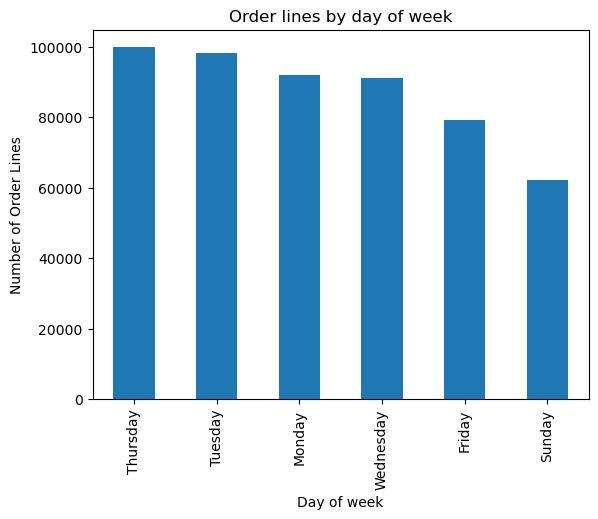

In [61]:
sales["DayOfWeek"].value_counts().plot(kind = "bar")
plt.title("Order lines by day of week")
plt.xlabel("Day of week")
plt.ylabel("Number of Order Lines")
plt.show()

There are no order lines on Saturday, and the company may be closed, or it doesn't process any orders that day. Monday through Thursday are the busiest and similar to each other (Thursday is the highest, about 100,000), while Friday and Sunday are lower (Sunday is the lowest, about 62,000). They should run promotions on the days with fewer orders, and if they close on Saturday, they should open for people to buy.

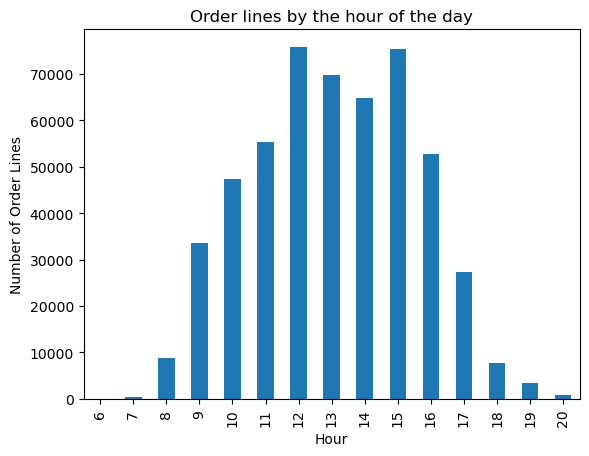

In [62]:
sales["Hour"].value_counts().sort_index().plot(kind = "bar")
plt.title("Order lines by the hour of the day")
plt.xlabel("Hour")
plt.ylabel("Number of Order Lines")
plt.show()

The orders start at 7:00 and end at 20:00, while most of them happen between 10:00 and 16:00. The peak hours are 12:00 and 15:00 with about, 75,000 order lines each. This could mean that customers order during office hours, as the customers may be business owners.

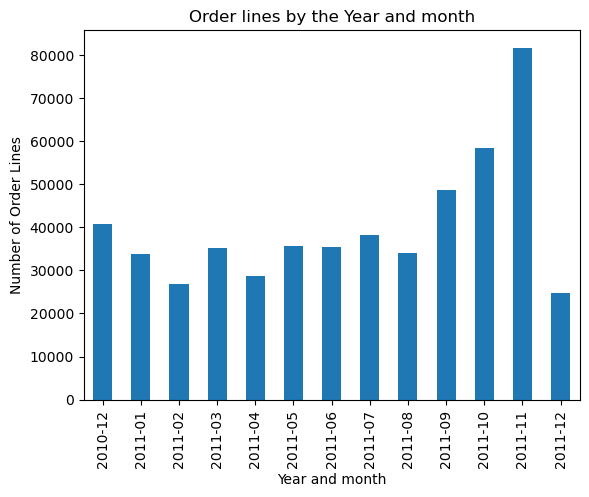

In [63]:
sales["YearMonth"].value_counts().sort_index().plot(kind = "bar")
plt.title("Order lines by the Year and month")
plt.xlabel("Year and month")
plt.ylabel("Number of Order Lines")
plt.show()

The data starts on 12-2010 and ends on 12-2011, after a whole year. The peak is in 11-2011, with around 82,000 order lines. In that month people buy things for the holidays, so that may be the reason it peaked, or maybe it's because of Black November. The order lines in December are about 25,000, but the data stops at 9-12-2011. The order lines were somewhat stable between 12-2010 and 08-2011, and they started increasing in 10-2011.

In [64]:
small_qty = sales[sales["Quantity"] <= 50]

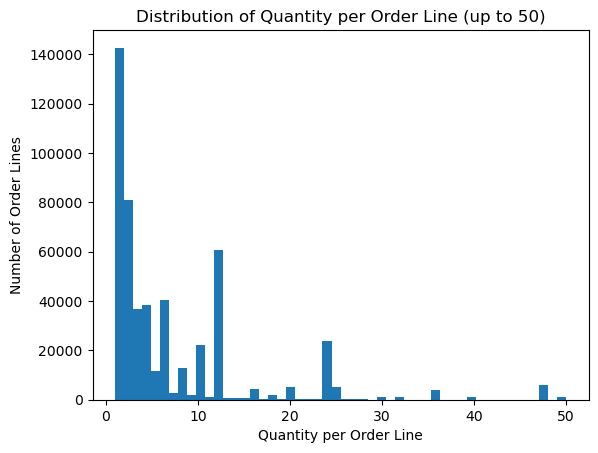

In [65]:
small_qty["Quantity"].plot(kind="hist", bins=50)
plt.title("Distribution of Quantity per Order Line (up to 50)")
plt.xlabel("Quantity per Order Line")
plt.ylabel("Number of Order Lines")
plt.show()

In [66]:
qty_prc = round(len(small_qty) / len(sales) * 100, 2)
print("Order lines with quantity 50 or less:", qty_prc, "%")

Order lines with quantity 50 or less: 97.68 %


97.68% of order lines have a quantity of 50 or less, so this chart covers almost everything. Quantity 1 is by far the most common, almost 142,000, then 2 is almost 81,000. After that, it's not a smooth drop. There are spikes at specific numbers: 12, 6, 24

In [67]:
small_price = sales[sales["UnitPrice"] <= 20]

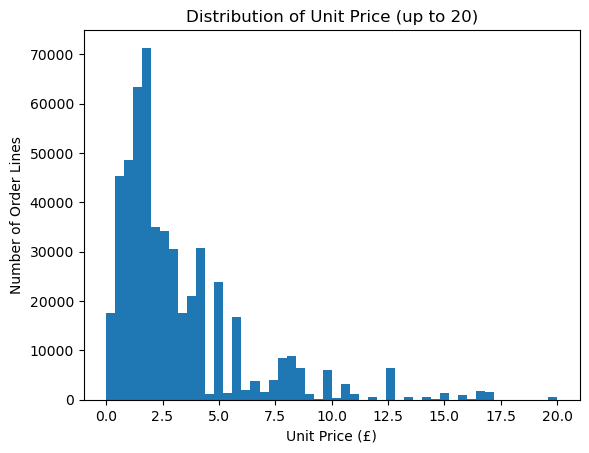

In [68]:
small_price["UnitPrice"].plot(kind="hist", bins=50)
plt.title("Distribution of Unit Price (up to 20)")
plt.xlabel("Unit Price (£)")
plt.ylabel("Number of Order Lines")
plt.show()

In [69]:
price_prc = round(len(small_price) / len(sales) * 100, 2)
print("Order lines with unit price 20 or less:", price_prc, "%")

Order lines with unit price 20 or less: 99.5 %


99.5% of order lines have a unit price of 20 or less. Almost nothing in this shop costs more than £20. The tallest bar is around £1.60–£2.00 for almost 71,000 lines. That’s the most common price. Most prices are between about £0.40 and £3. That’s where the big bars are. After about £3 the bars get smaller, but there are separate spikes at around £4–5, £6, £8, £10 and £12.50 instead of a smooth drop.

## Part 3: Bivariate Analysis
There is no target column in the dataset, so Revenue is the target column since it will help the company understand sales performance.
Revenue is the UnitPrice x Quantity.

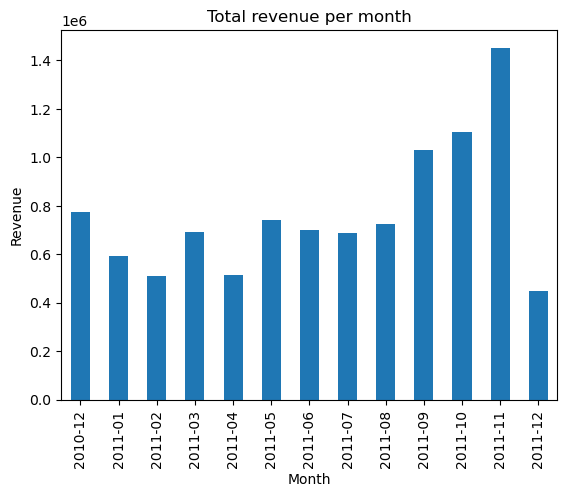

In [70]:
sales.groupby("YearMonth")["Revenue"].sum().plot(kind = "bar")
plt.title("Total revenue per month")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.show()

Revenue is stable from December 2010 till August 2011, then it starts rising in September 2011, as it peaks in November 2011 (about 1.45 mil), as we saw in the previous chart. The lowest months are February 2011 and April 2011, with about 510,000 each. September has similar revenue as October with fewer order lines, which suggests bigger orders, probably from wholesalers stocking up for Christmas.

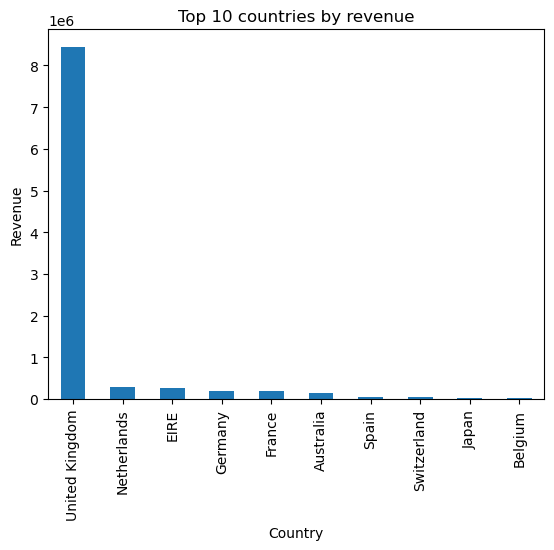

In [71]:
sales.groupby("Country")["Revenue"].sum().sort_values(ascending=False).head(10).plot(kind = "bar")
plt.title("Top 10 countries by revenue")
plt.xlabel("Country")
plt.ylabel("Revenue")
plt.show()

The UK has the highest revenue, with about 8.4 million. The Netherlands is second by revenue, even though it was sixth by order lines in the first chart, so its orders are bigger. I would recommend focusing on the Netherlands and growing big customers there.

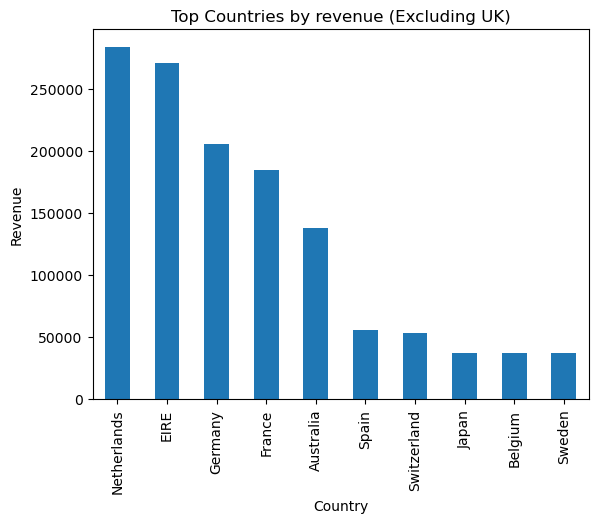

In [72]:
sales[non_UK_sales].groupby("Country")["Revenue"].sum().sort_values(ascending=False).head(10).plot(kind = "bar")
plt.title("Top Countries by revenue (Excluding UK)")
plt.xlabel("Country")
plt.ylabel("Revenue")
plt.show()

The Netherlands and EIRE lead with about 285,000, followed by Germany and France. Australia is 5th By revenue but only 9th by order lines, so it probably has bigger orders.After, the top 5 there's a big drop with Spain dropping to 55,000.

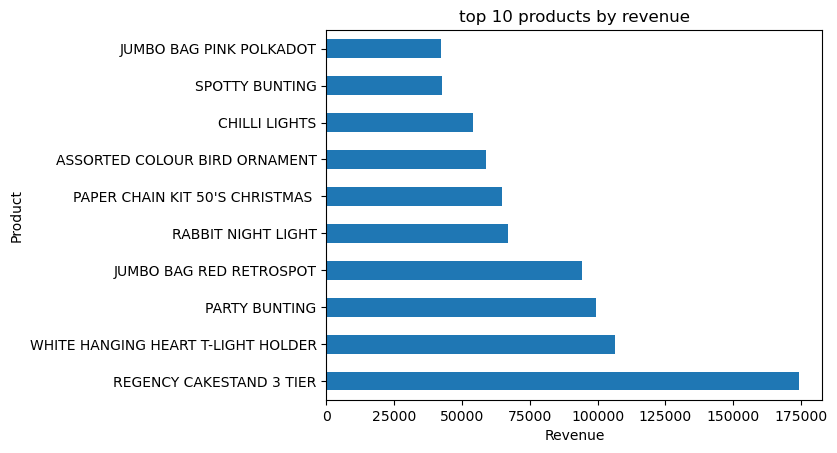

In [73]:
sales.groupby("Description")["Revenue"].sum().sort_values(ascending=False).head(10).plot(kind = "barh")
plt.title("top 10 products by revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")
plt.show()

Regency Cakestand 3 tier is #1 with about 174,000, while #2 is about 106,000. The top items are mostly party and home decoration items. Even the best products are under 2% of total revenue, so the company depends on many different products, not a few.

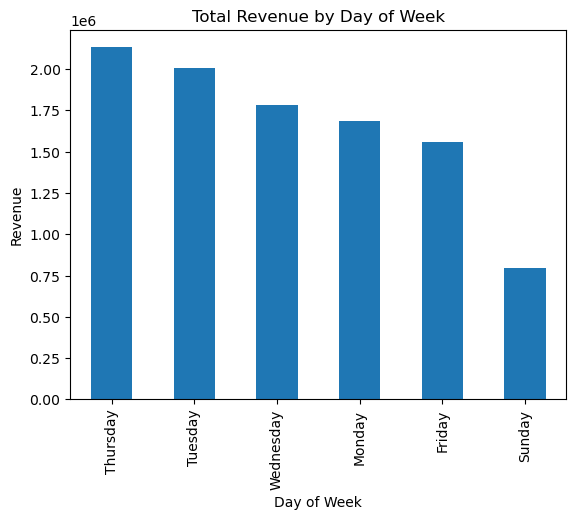

In [74]:
sales.groupby("DayOfWeek")["Revenue"].sum().sort_values(ascending=False).plot(kind = "bar")
plt.title("Total Revenue by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Revenue")
plt.show()

Thursday has the highest revenue (about 2.1 million), and Sunday the lowest (about 0.8 million). Sunday has about 20% fewer order lines than Friday but only about half the revenue, so its orders are smaller. This suggests Sunday shoppers are probably individuals rather than businesses.

In [75]:
cancel_rows = df[cancelled]

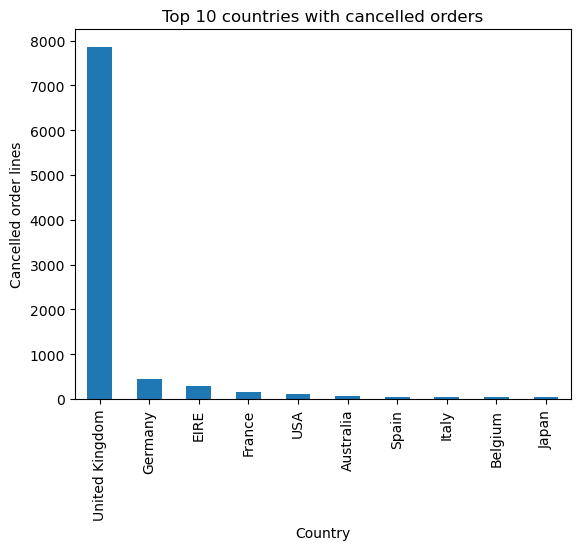

In [76]:
cancel_rows["Country"].value_counts().head(10).plot(kind="bar")
plt.title("Top 10 countries with cancelled orders")
plt.xlabel("Country")
plt.ylabel("Cancelled order lines")
plt.show()

The UK has by far the most cancelled order lines, about 7,850. That's expected, because the UK has by far the most order lines overall shown in the first chart. The USA appears in this top 10 even though it's not in the top 10 by order lines, which suggests a high share of USA orders gets cancelled. 

## Part 4: Missing Data and Outliers

In [81]:
print("Stock adjustments with no description:", neg_not_canc["Description"].isnull().sum())

Stock adjustments with no description: 862


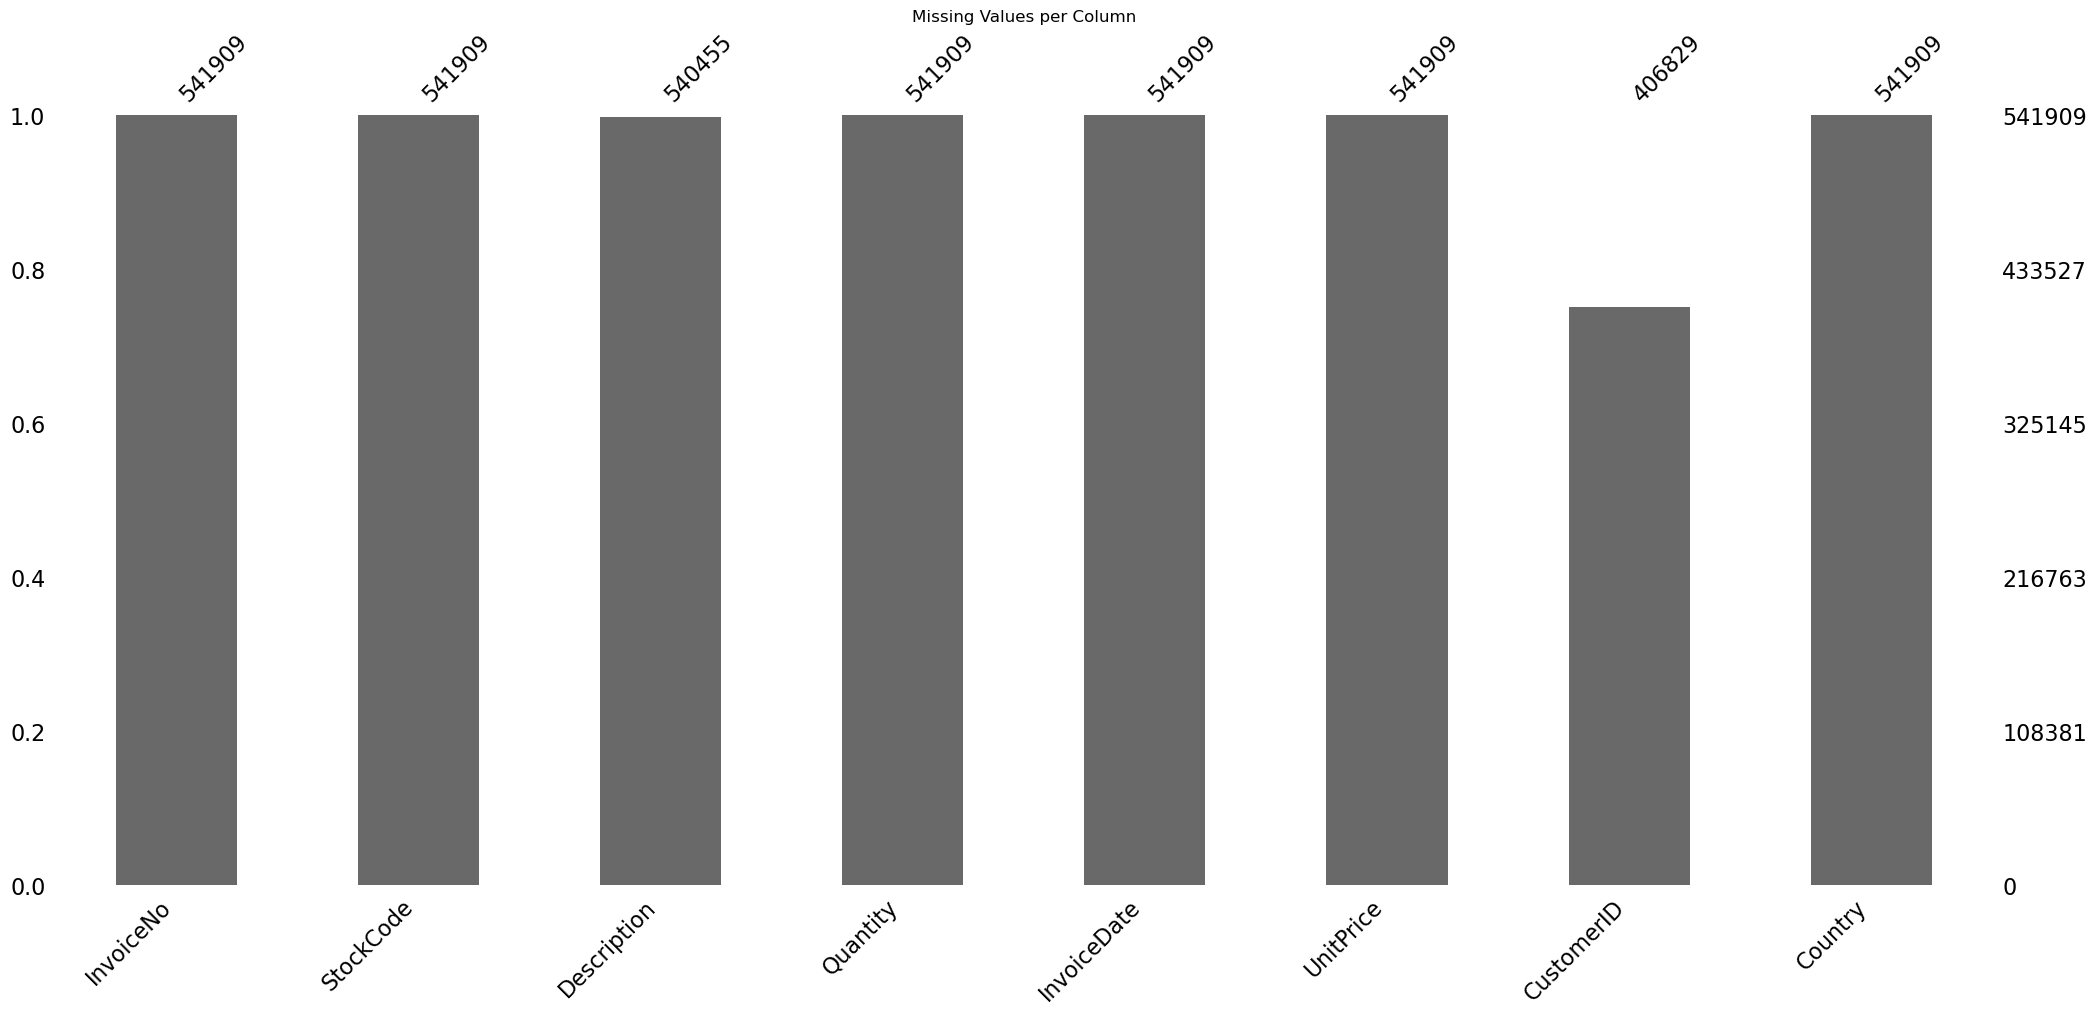

In [80]:
msno.bar(df)
plt.title("Missing Values per Column")
plt.show()

CustomerID has 135,080 missing, about 25%. The possible reasons are that guest buyers without an account and internal entries like the stock adjustments  none of the 1,336 (negative quantity but not cancelled) had a customerID. The rows stay in sales, because they're still real sales and count for revenue, products, countries and time, but they can't be used for customer segmentation, because we don't know who bought the products. Also, the description is missing 1,454 (0.27%); most of our stock adjustment rows, 862 of the 1,336, had no description, and all had a price of 0. Those rows were already removed from sales by the filter. Missing descriptions don’t affect the sales analysis.

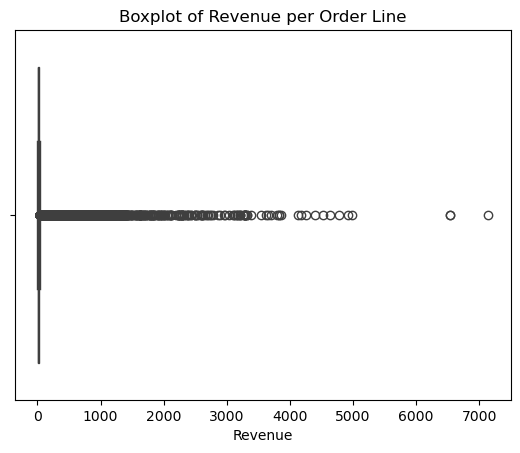

In [85]:
sns.boxplot(x=sales["Revenue"])
plt.title("Boxplot of Revenue per Order Line")
plt.xlabel("Revenue")
plt.show()

In [89]:
q1 = sales["Revenue"].quantile(0.25)
q3 = sales["Revenue"].quantile(0.75)

In [95]:
qr = stats.iqr(sales["Revenue"])
upper = q3 + 1.5 * iqr

In [96]:
outliers = sales[sales["Revenue"] > upper]

In [97]:
print(round(upper, 2))

38.4


In [98]:
print(len(outliers))

41121


In [99]:
print(round(len(outliers) / len(sales) * 100, 2))

7.87
